# Benchmarks: does the sparse tau-domain inverse earn its complexity?

`clif` carries two general inverse algorithms under one hood:

- **native FLS** (`clif.inverse.fls.fls_inverse`) --- the simple, direct
  implementation.  Short, easy to audit, no precomputation.
- **sparse FLS** (`clif.inverse.TauInverse`) --- the tau-domain engine.  Far more
  code, a per-signature setup cost, and JIT-compiled kernels.

The extra machinery has to pay for itself twice over to be worth keeping:

1. **Speed.**  Where both algorithms run, sparse FLS should be faster, and the
   margin should widen with dimension.
2. **Reach.**  Native FLS gives out at some dimension.  Past that point sparse
   FLS is not an optimization at all --- it is the only thing that runs.

A third line, `A.inverse()`, is the dispatcher the user actually calls.  At low
dimension it selects neither of the above, so plotting it shows what the
programmatic choice costs relative to the general engines it replaces.

Everything below is Euclidean signature.  Each timed call is preceded by warmup
calls so no Numba compilation lands inside a measurement, and `TauInverse`
construction happens outside the timing loop --- it is cached per signature by
`get_inverter`, so a user pays it once per algebra, not once per inverse.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from clif.context import Cl
from clif.multivector import Accum
#from clif.inverse import get_inverter
from clif.inverse.fls import fls_inverse

N_WARMUP = 3
N_RUNS   = 30
DIMS     = list(range(2, 12))      # Cl(2) .. Cl(11)

print(f"warmup {N_WARMUP}, timed runs {N_RUNS}, dimensions {DIMS[0]}-{DIMS[-1]}")

warmup 3, timed runs 30, dimensions 2-11


## Calling conventions

`TauInverse.inverse` may take an `Accum` or a raw coefficient array depending on
how the engine was last refactored, so probe it once rather than assume.  The
adapter returned here is what the timing loop calls.

In [2]:
def tau_adapter(d):
    """Return (inverter, call, label) for dimension d, Euclidean signature."""
    inv = get_inverter([1] * d)
    A = Accum.random()
    candidates = [
        ("inverse(Accum)", lambda X, _i=inv: _i.inverse(X)),
        ("inverse(Reg)",   lambda X, _i=inv: _i.inverse(X.Reg)),
    ]
    for label, call in candidates:
        try:
            call(A)
        except Exception:
            continue
        return inv, call, label
    raise RuntimeError("no working call convention for TauInverse.inverse")


def as_accum(result):
    """Normalize an inverse result to an Accum so residuals compare like for like."""
    if isinstance(result, Accum):
        return result
    B = Accum()
    B.Reg[:] = np.asarray(result, dtype=float)
    return B


#Cl(6)
#_, _tau_call, _label = tau_adapter(6)
#print(f"TauInverse called as: {_label}")

## Timing harness

`bench` returns microseconds per call.  `attempt` runs a single call and reports
whether the algorithm succeeded, so a failure becomes a recorded data point
rather than a dead notebook --- the point of the exercise is to find where
native FLS stops.

In [3]:
def bench(fn, A, n_warmup=N_WARMUP, n_runs=N_RUNS):
    """Mean microseconds per call, after warmup."""
    for _ in range(n_warmup):
        fn(A)
    t0 = time.perf_counter()
    for _ in range(n_runs):
        fn(A)
    return (time.perf_counter() - t0) / n_runs * 1e6


def residual(A, iA):
    """Max off-scalar coefficient of A * iA; zero for an exact inverse."""
    return max(abs((A * as_accum(iA)).Reg[1:]))


def attempt(fn, A, timed=True):
    """Return (microseconds, residual, reason).  Single untimed call when timed is False."""
    try:
        t0 = time.perf_counter()
        iA = fn(A)
        single = (time.perf_counter() - t0) * 1e6
    except Exception as exc:
        return np.nan, np.nan, f"{type(exc).__name__}: {exc}"
    if not timed:
        return single, residual(A, iA), None
    return bench(fn, A), residual(A, iA), None


## Sweep

In [4]:
from clif.inverse.tau_api import get_inverter

TOL = 1e-6      # generous: anything failing this is wrong, not merely imprecise

names   = ["native_fls", "sparse_fls", "dispatched"]
times   = {n: [] for n in names}
resids  = {n: [] for n in names}
notes   = {n: {} for n in names}
alive   = {n: True for n in names}
dims_run = []

for d in DIMS:
    if not any(alive.values()):
        break
    Cl(d)
    A = Accum.random()
    dims_run.append(d)

    tau_call = tau_adapter(d)[1] if 4 <= d <= 11 else None   # construction outside the timing

    algos = {
        "native_fls": (fls_inverse, None),
        "sparse_fls": (tau_call, "outside supported range d = 4..11"),
        "dispatched": (lambda X: X.inverse(), None),
    }
    for name, (fn, reason) in algos.items():
        if not alive[name] or fn is None:
            times[name].append(np.nan); resids[name].append(np.nan)
            if alive[name] and reason:
                notes[name][d] = reason
            continue
        t, r, why = attempt(fn, A, timed=(d <= 11))
        if why or r > TOL:
            alive[name] = False
            notes[name][d] = why or f"residual {r:.2e} exceeds {TOL:.0e}"
            times[name].append(np.nan); resids[name].append(np.nan)
            continue
        times[name].append(t); resids[name].append(r)

    print(f"Cl({d:2d}) done")

Cl( 2) done
Cl( 3) done
Cl( 4) done
Cl( 5) done
Cl( 6) done
Cl( 7) done
Cl( 8) done
Cl( 9) done
Cl(10) done
Cl(11) done


## Where native FLS stops

The reach claim stands or falls here.  Anything printed below is a dimension at
which the simple algorithm is unavailable and the sparse engine is the only
route to an inverse.

In [5]:
for name in names:
    if notes[name]:
        for d, why in sorted(notes[name].items()):
            print(f"{name:12s}  Cl({d:2d})  {why}")
    else:
        print(f"{name:12s}  ran at every dimension tested")

native_fls    Cl(10)  residual 1.85e-01 exceeds 1e-06
sparse_fls    Cl( 2)  outside supported range d = 4..11
sparse_fls    Cl( 3)  outside supported range d = 4..11
dispatched    ran at every dimension tested


## Timing table

`speedup` is native FLS time divided by sparse FLS time: greater than one means
the extra machinery paid off at that dimension.

In [6]:
header = (f"{'d':>4}  {'native (us)':>13}  {'nat resid':>11}  {'sparse (us)':>13}  "
          f"{'spa resid':>11}  {'speedup':>9}")
print(header)
print("-" * len(header))
for i, d in enumerate(DIMS):
    nat, spa = times['native_fls'][i], times['sparse_fls'][i]
    rn, rs   = resids['native_fls'][i], resids['sparse_fls'][i]
    speed = nat / spa if (spa == spa and nat == nat and spa > 0) else float('nan')
    def fmt(x, w, p=1):
        return f"{'--':>{w}}" if x != x else f"{x:{w}.{p}f}"
    def res(x, w):
        if x != x:
            return f"{'--':>{w}}"
        return f"{x:{w-1}.1e}" + ("!" if x > TOL else " ")
    print(f"  {d:2d}  {fmt(nat,13)}  {res(rn,11)}  {fmt(spa,13)}  "
          f"{res(rs,11)}  {fmt(speed,9,2)}")
print(f"\n'!' marks a residual above {TOL:.0e} -- a timing there is timing a wrong answer.")

   d    native (us)    nat resid    sparse (us)    spa resid    speedup
-----------------------------------------------------------------------
   2           19.8     3.2e-16              --           --         --
   3           20.4     8.3e-17              --           --         --
   4           49.8     1.5e-14             6.1     3.7e-16        8.13
   5           56.2     1.2e-14             9.4     5.8e-16        6.00
   6          173.1     6.2e-14            39.4     5.1e-16        4.40
   7          383.3     5.6e-14           137.0     4.5e-16        2.80
   8         2159.8     4.6e-09           637.4     2.5e-15        3.39
   9         7831.9     8.8e-08          2610.2     4.9e-15        3.00
  10             --           --        10819.5     4.2e-15          --
  11             --           --        55428.4     9.6e-15          --

'!' marks a residual above 1e-06 -- a timing there is timing a wrong answer.


## Timing plot

The native FLS line ends where the algorithm does.  Beyond that point there is
nothing to compare against, which is the argument for the sparse engine in its
strongest form.

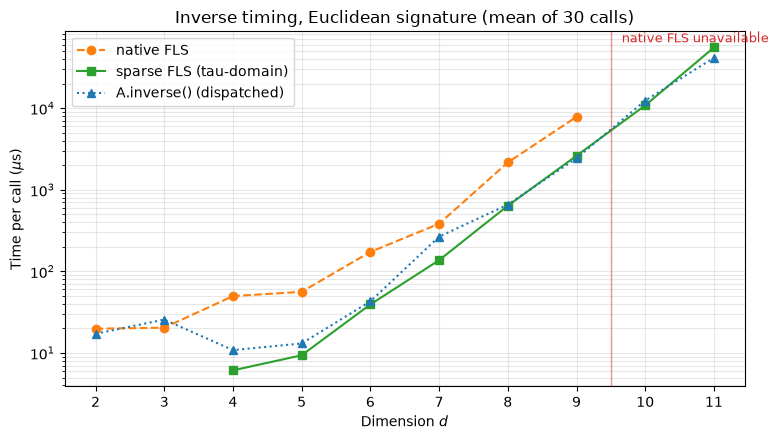

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))

styles = {
    "native_fls": dict(marker='o', linestyle='--', color='tab:orange', label='native FLS'),
    "sparse_fls": dict(marker='s', linestyle='-',  color='tab:green',  label='sparse FLS (tau-domain)'),
    "dispatched": dict(marker='^', linestyle=':',  color='tab:blue',   label='A.inverse() (dispatched)'),
}
for name, style in styles.items():
    ax.semilogy(DIMS, times[name], **style)

alive = [d for d, t in zip(DIMS, times['native_fls']) if t == t]
if alive and alive[-1] < DIMS[-1]:
    ax.axvline(alive[-1] + 0.5, color='tab:red', linewidth=1, alpha=0.5)
    ax.text(alive[-1] + 0.6, ax.get_ylim()[1], ' native FLS unavailable',
            color='tab:red', va='top', fontsize=9)

ax.set_xlabel('Dimension $d$')
ax.set_ylabel('Time per call ($\\mu$s)')
ax.set_title(f'Inverse timing, Euclidean signature (mean of {N_RUNS} calls)')
ax.set_xticks(DIMS)
ax.legend()
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

## Speedup, isolated

Time is a noisy quantity and a log axis flatters everything.  The ratio is the
honest summary of claim 1: it should exceed one and grow.

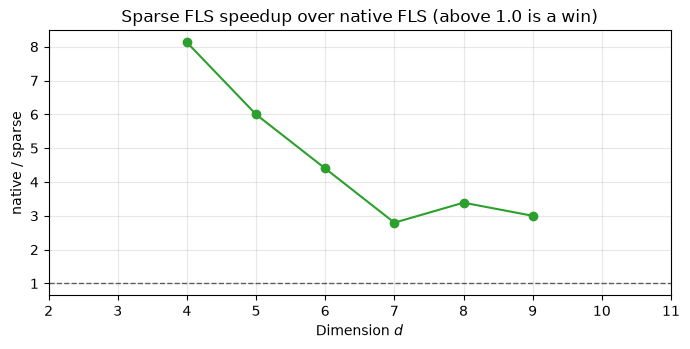

In [8]:
ratio = [n / s if (n == n and s == s and s > 0 and rn <= TOL and rs <= TOL) else np.nan
         for n, s, rn, rs in zip(times['native_fls'], times['sparse_fls'],
                                 resids['native_fls'], resids['sparse_fls'])]

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(DIMS, ratio, marker='o', color='tab:green')
ax.axhline(1.0, color='k', linewidth=1, linestyle='--', alpha=0.6)
ax.set_xlabel('Dimension $d$')
ax.set_ylabel('native / sparse')
ax.set_title('Sparse FLS speedup over native FLS (above 1.0 is a win)')
ax.set_xticks(DIMS)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Operation counts

Wall-clock time depends on the machine.  `TauInverse.cost` reports the work the
engine actually schedules, which is the machine-independent version of the same
claim.

In [9]:
print(f"{'d':>4}  {'sparse cost':>14}")
print("-" * 20)
for d in DIMS:
    if not 4 <= d <= 11:
        print(f"  {d:2d}  {'--':>14}")
        continue
    inv = get_inverter([1] * d)
    c = inv.cost() if callable(getattr(type(inv), 'cost', None)) else inv.cost
    print(f"  {d:2d}  {str(c):>14}")

   d     sparse cost
--------------------
   2              --
   3              --
   4  {'table_bytes': 51, 'mults_per_mul': 16, 'sweep': 6, 'step_down': 56, 'step_up': 96, 'total': 158}
   5  {'table_bytes': 51, 'mults_per_mul': 64, 'sweep': 24, 'step_down': 208, 'step_up': 384, 'total': 616}
   6  {'table_bytes': 1486, 'mults_per_mul': 352, 'sweep': 732, 'step_down': 928, 'step_up': 1792, 'total': 3452}
   7  {'table_bytes': 1486, 'mults_per_mul': 1408, 'sweep': 2928, 'step_down': 3648, 'step_up': 7168, 'total': 13744}
   8  {'table_bytes': 30108, 'mults_per_mul': 6784, 'sweep': 40824, 'step_down': 15488, 'step_up': 30720, 'total': 87032}
   9  {'table_bytes': 30108, 'mults_per_mul': 27136, 'sweep': 163296, 'step_down': 61696, 'step_up': 122880, 'total': 347872}
  10  {'table_bytes': 535096, 'mults_per_mul': 119296, 'sweep': 1670640, 'step_down': 254464, 'step_up': 507904, 'total': 2433008}
  11  {'table_bytes': 535096, 'mults_per_mul': 477184, 'sweep': 6682560, 'step_down': 101683

## Accuracy

Speed is only a win if the answer is still right.  Residual is the largest
off-scalar coefficient of $A A^{-1}$, which is zero for an exact inverse.

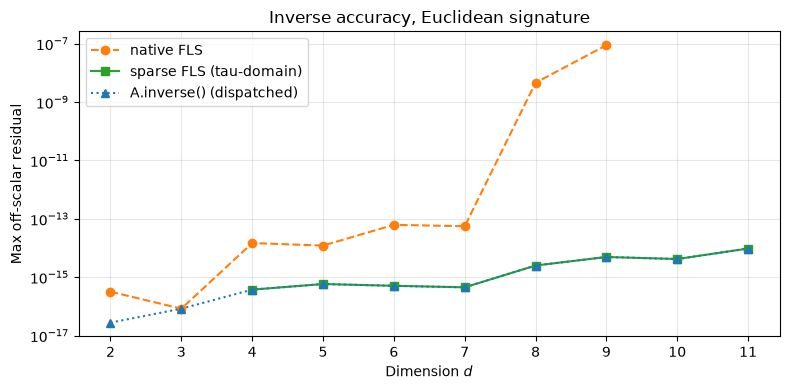

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, style in styles.items():
    ax.semilogy(DIMS, resids[name], marker=style['marker'],
                linestyle=style['linestyle'], color=style['color'], label=style['label'])
ax.set_xlabel('Dimension $d$')
ax.set_ylabel('Max off-scalar residual')
ax.set_title('Inverse accuracy, Euclidean signature')
ax.set_xticks(DIMS)
ax.legend()
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()